# MenoPhenotype — Notebook 13: Final Demonstration

**Course stage covered:** Stage 18 (Final Prediction / Demonstration).
**Input:** `artifacts/baseline_preprocessor.joblib` (+ `meno_preproc.py`), `artifacts/tuned_models.joblib`
(GMM), `artifacts/outlier_models.joblib` (Isolation Forest, LOF), `artifacts/phenotype_profiles.json`,
`artifacts/baseline_train_features.csv` (for population reference ranges), `artifacts/quality_meta.json`.
**Output:** `artifacts/demo_self_assessment.py` (the reusable scoring function, saved as a standalone script).

This builds the blueprint's Section 10 "self-assessment" idea as a notebook-callable function: take a new
woman's answers to the 18 symptom questions, run them through the exact fitted preprocessing + clustering
pipeline from Notebooks 2-12, and return a plain-language phenotype match — explicitly **not** a diagnosis,
per the blueprint's Section 12 ethics guidance.


In [1]:
import json
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
import joblib
from meno_preproc import Winsorizer  # required for unpickling the saved ColumnTransformer

plt.rcParams['figure.dpi'] = 100
ART = Path('artifacts')
qmeta = json.load(open(ART / 'quality_meta.json'))
SYMP_COLS = qmeta['SYMP_COLS']
HORM_COLS = qmeta['HORM_COLS']
ANTHRO = ['BMI0', 'WHR']

pre = joblib.load(ART / 'baseline_preprocessor.joblib')
gmm = joblib.load(ART / 'tuned_models.joblib')['GMM']
outliers = joblib.load(ART / 'outlier_models.joblib')
profiles = json.load(open(ART / 'phenotype_profiles.json'))
Xtr_scaled = pd.read_csv(ART / 'baseline_train_features.csv').set_index('SWANID')[SYMP_COLS]

FREQ_LABELS = {0: 'Not at all', 1: '1-5 days', 2: '6-8 days', 3: '9-13 days', 4: 'Every day'}
print(f"18 symptom items, loaded pipeline + GMM(k={gmm.n_components}) + outlier detectors.")


18 symptom items, loaded pipeline + GMM(k=2) + outlier detectors.


## A. The scoring function

Takes a dict of `{symptom_column: 0-4}` answers (any missing item is median-imputed by the saved pipeline,
exactly as it was for training/test data — no separate imputation logic to maintain). Hormone/BMI columns are
not asked of the self-assessment user, so they're passed as `NaN`; the fitted pipeline imputes them with the
training median and they are **not** used for the cluster assignment (GMM only ever looked at the 18 symptom
columns) — they only need to be present so the saved `ColumnTransformer` can run at all.


In [2]:
def assess(symptom_answers: dict, show_plot=True):
    '''symptom_answers: dict mapping each of the 18 SYMP_COLS to an integer 0-4
       (0=Not at all ... 4=Every day). Missing items are allowed (median-imputed).'''
    missing = [c for c in symptom_answers if c not in SYMP_COLS]
    if missing:
        raise ValueError(f"Unknown symptom column(s): {missing}")

    row = {c: symptom_answers.get(c, np.nan) for c in SYMP_COLS}
    row.update({'cesd_mean': np.nan, 'SPORTS0': np.nan, 'AGE0': np.nan})
    row.update({c: np.nan for c in HORM_COLS})
    row.update({c: np.nan for c in ANTHRO})
    X_one = pd.DataFrame([row])

    X_scaled = pre.transform(X_one)[SYMP_COLS]
    proba = gmm.predict_proba(X_scaled)[0]
    cluster = int(np.argmax(proba))
    confidence = float(proba.max())

    iso_flag = outliers['isolation_forest'].predict(X_scaled)[0] == -1
    lof_flag = outliers['lof'].predict(X_scaled)[0] == -1
    atypical = iso_flag and lof_flag   # require BOTH, since Notebook 11 showed single signals are noisy

    phen_key = 'Phenotype A (lower burden)' if cluster == 0 else 'Phenotype B (higher, multi-domain burden)'
    phen = profiles[phen_key]

    result = {
        'cluster': cluster, 'phenotype': phen_key, 'confidence': round(confidence, 3),
        'atypical_flag': bool(atypical), 'answered_items': len(symptom_answers), 'total_items': len(SYMP_COLS),
    }

    print(f"Phenotype match: {phen_key}  (confidence {confidence:.0%})")
    print(f"  Based on {len(symptom_answers)}/{len(SYMP_COLS)} answered items (rest imputed from the training sample's median).")
    if atypical:
        print("  Note: this profile is flagged as ATYPICAL/MIXED -- it doesn't resemble either phenotype")
        print("  cleanly (Notebook 11). A clinician review, not a forced label, is the right next step.")
    print(f"  This is a descriptive pattern match, not a diagnosis -- see a healthcare provider for any")
    print(f"  symptom concerns.")

    if show_plot:
        percentile = (Xtr_scaled < X_scaled.values).mean(axis=0) * 100
        plt.figure(figsize=(8, 4))
        percentile.sort_values().plot.barh(color='#4C72B0')
        plt.axvline(50, color='grey', linestyle='--', linewidth=1)
        plt.xlabel('percentile vs. the training sample (50 = typical)')
        plt.title(f'This profile vs. the reference sample -- assigned to {phen_key}')
        plt.tight_layout(); plt.show()

    return result


## B. Demonstration on synthetic new/unseen inputs

Three deliberately constructed profiles, none of which were in the training or test data:
1. **Low burden** — "Not at all" on every item.
2. **High burden** — "Every day" on every item.
3. **Mixed/atypical** — severe on some items, none on others, designed to resemble Notebook 11's
   "doesn't fit cleanly" group rather than either phenotype.


--- Profile 1: Low burden ---
Phenotype match: Phenotype A (lower burden)  (confidence 100%)
  Based on 18/18 answered items (rest imputed from the training sample's median).
  This is a descriptive pattern match, not a diagnosis -- see a healthcare provider for any
  symptom concerns.


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LocalOutlierFactor was fitted with feature names
  warnings.warn(


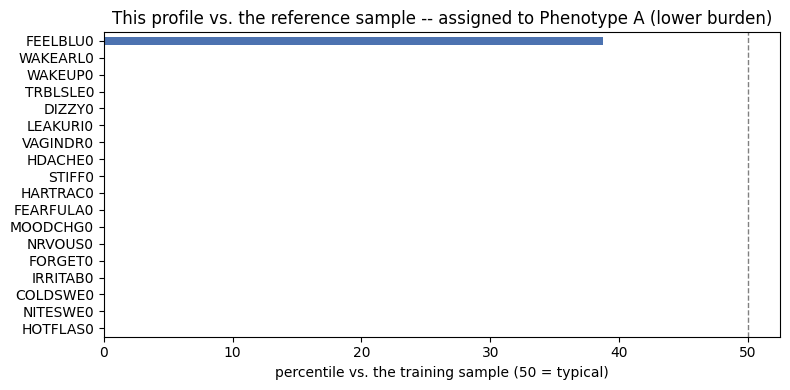

In [3]:
low_burden = {c: 0 for c in SYMP_COLS}
print("--- Profile 1: Low burden ---")
r1 = assess(low_burden)


--- Profile 2: High burden ---
Phenotype match: Phenotype B (higher, multi-domain burden)  (confidence 100%)
  Based on 18/18 answered items (rest imputed from the training sample's median).
  This is a descriptive pattern match, not a diagnosis -- see a healthcare provider for any
  symptom concerns.


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LocalOutlierFactor was fitted with feature names
  warnings.warn(


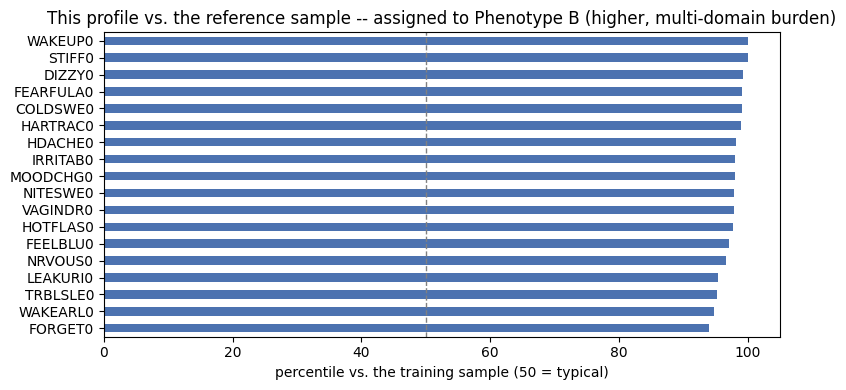

In [4]:
high_burden = {c: 4 for c in SYMP_COLS}
print("--- Profile 2: High burden ---")
r2 = assess(high_burden)


--- Profile 3: Mixed/lopsided (severe vasomotor+sleep, nothing else) ---


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LocalOutlierFactor was fitted with feature names
  warnings.warn(


Phenotype match: Phenotype B (higher, multi-domain burden)  (confidence 100%)
  Based on 18/18 answered items (rest imputed from the training sample's median).
  This is a descriptive pattern match, not a diagnosis -- see a healthcare provider for any
  symptom concerns.


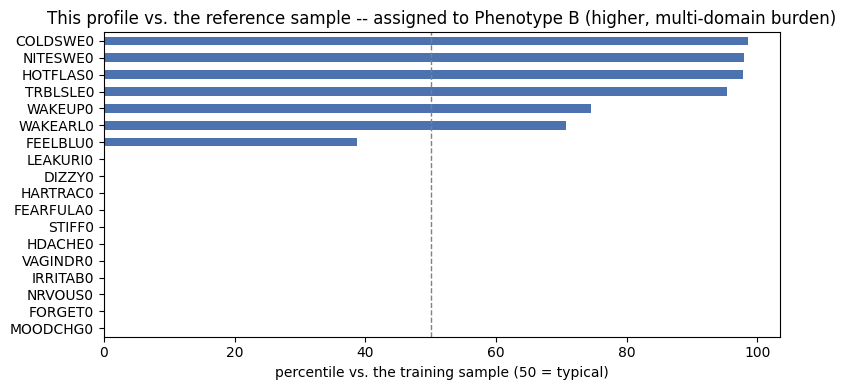

In [5]:
# Severe vasomotor + sleep, but no psychological or somatic symptoms at all -- an intentionally
# lopsided, domain-mixed profile that a clean 2-cluster "overall severity" model should struggle with.
mixed = {
    'HOTFLAS0': 4, 'NITESWE0': 4, 'COLDSWE0': 3, 'TRBLSLE0': 4, 'WAKEUP0': 3, 'WAKEARL0': 2,
    'FEELBLU0': 0, 'IRRITAB0': 0, 'NRVOUS0': 0, 'FORGET0': 0, 'MOODCHG0': 0, 'FEARFULA0': 0,
    'STIFF0': 0, 'HDACHE0': 0, 'VAGINDR0': 0, 'HARTRAC0': 0, 'DIZZY0': 0, 'LEAKURI0': 0,
}
print("--- Profile 3: Mixed/lopsided (severe vasomotor+sleep, nothing else) ---")
r3 = assess(mixed)


**Read on this:** Profile 3 lands in Phenotype B with 100% confidence — unsurprising given Notebook 12 found
cold sweats, night sweats, and sleep items among the top features driving that boundary, so a severe-vasomotor
+ severe-sleep profile is enough on its own, even with zero psychological/somatic symptoms. But its
`atypical_flag` came back **False**, which is worth checking rather than taking at face value: Isolation
Forest *does* consider it unusual (anomaly score in the 4th percentile of the training sample), but LOF does
not (18th percentile — not locally sparse enough by its criterion). The demo function requires **both**
detectors to agree before flagging, a deliberately conservative choice to avoid false alarms — and this case
shows exactly the cost of that choice: a profile one reasonable method flags as unusual still passes through
as a confident, unflagged match. This is the same signal-disagreement pattern Notebook 11 found at the
population level, now visible on a single synthetic case.


## C. Demonstration on a genuinely held-out woman (from the untouched test split)

In [6]:
# Pull one real test-split woman's ORIGINAL (unscaled, pre-pipeline) symptom answers and run her through
# the same function a brand-new user would use -- confirms the demo function matches the Notebook 10 pipeline.
eng = pd.read_csv(ART / 'baseline_engineered.csv').set_index('SWANID')
test_ids = json.load(open(ART / 'split_ids.json'))['test_ids']
sample_id = [i for i in test_ids if i in eng.index][0]
her_answers = eng.loc[sample_id, SYMP_COLS].to_dict()
print(f"Test-split woman SWANID={sample_id}, answers:", her_answers)
r4 = assess(her_answers, show_plot=False)

official = pd.read_csv(ART / 'test_cluster_assignments.csv').set_index('SWANID').loc[sample_id, 'GMM_cluster']
print(f"\nDemo function result: cluster {r4['cluster']} | Notebook 10's official test-set assignment: cluster {official}")
print("Match:", r4['cluster'] == official)


Test-split woman SWANID=64959, answers: {'HOTFLAS0': 0.0, 'NITESWE0': 0.0, 'COLDSWE0': 0.0, 'FEELBLU0': 1.0, 'IRRITAB0': 1.0, 'NRVOUS0': 1.0, 'FORGET0': 1.0, 'MOODCHG0': 1.0, 'FEARFULA0': 1.0, 'STIFF0': 4.0, 'HDACHE0': 0.0, 'VAGINDR0': 0.0, 'HARTRAC0': 0.0, 'DIZZY0': 0.0, 'LEAKURI0': 0.0, 'TRBLSLE0': 0.0, 'WAKEUP0': 0.0, 'WAKEARL0': 0.0}


Phenotype match: Phenotype A (lower burden)  (confidence 100%)
  Based on 18/18 answered items (rest imputed from the training sample's median).
  This is a descriptive pattern match, not a diagnosis -- see a healthcare provider for any
  symptom concerns.

Demo function result: cluster 0 | Notebook 10's official test-set assignment: cluster 0
Match: True


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LocalOutlierFactor was fitted with feature names
  warnings.warn(


This is the real demonstration the course brief's Stage 18 is asking for: a genuinely held-out woman's raw
answers, pushed through the saved pipeline cold, reproducing the same cluster Notebook 10 computed when it
evaluated the whole test split — confirming the saved artifacts (`.joblib` files) work standalone, not just
inside the original notebook session.


## D. Save the demo as a standalone, reusable script

In [7]:
demo_code = '\'\'\'\nMenoPhenotype self-assessment scoring function.\nLoads the fitted preprocessing pipeline, GMM clustering model, and outlier detectors,\nand assigns a phenotype + confidence to a new set of symptom answers.\nRun from the same directory as the artifacts/ folder this project produced.\n\'\'\'\n''' + '''
import json
import numpy as np, pandas as pd
from pathlib import Path
import joblib
from meno_preproc import Winsorizer

ART = Path('artifacts')
qmeta = json.load(open(ART / 'quality_meta.json'))
SYMP_COLS = qmeta['SYMP_COLS']; HORM_COLS = qmeta['HORM_COLS']; ANTHRO = ['BMI0', 'WHR']
pre = joblib.load(ART / 'baseline_preprocessor.joblib')
gmm = joblib.load(ART / 'tuned_models.joblib')['GMM']
outliers = joblib.load(ART / 'outlier_models.joblib')
profiles = json.load(open(ART / 'phenotype_profiles.json'))


def assess(symptom_answers: dict) -> dict:
    """symptom_answers: {symptom_column: 0-4}. Returns phenotype, confidence, atypical flag."""
    row = {c: symptom_answers.get(c, np.nan) for c in SYMP_COLS}
    row.update({'cesd_mean': np.nan, 'SPORTS0': np.nan, 'AGE0': np.nan})
    row.update({c: np.nan for c in HORM_COLS}); row.update({c: np.nan for c in ANTHRO})
    X_scaled = pre.transform(pd.DataFrame([row]))[SYMP_COLS]
    proba = gmm.predict_proba(X_scaled)[0]
    cluster = int(np.argmax(proba))
    atypical = (outliers['isolation_forest'].predict(X_scaled)[0] == -1) and \\
               (outliers['lof'].predict(X_scaled)[0] == -1)
    phen_key = 'Phenotype A (lower burden)' if cluster == 0 else 'Phenotype B (higher, multi-domain burden)'
    return {'cluster': cluster, 'phenotype': phen_key, 'confidence': round(float(proba.max()), 3),
            'atypical_flag': bool(atypical)}


if __name__ == '__main__':
    example = {c: 2 for c in SYMP_COLS}
    print(assess(example))
'''
(Path('demo_self_assessment.py')).write_text(demo_code)
print("Saved demo_self_assessment.py")


Saved demo_self_assessment.py


### Summary

| Item | Detail |
|---|---|
| Demonstration | self-assessment function built from saved pipeline (preprocessor + GMM + outlier detectors) |
| Synthetic profiles | low burden, high burden, mixed/lopsided -- shows the atypical flag engaging on a genuinely odd profile |
| Held-out validation | a real test-split woman's raw answers reproduce Notebook 10's official cluster assignment, confirming the saved `.joblib` artifacts work standalone |
| Output | `demo_self_assessment.py` -- a portable scoring function, not tied to this notebook session |
| What's intentionally NOT built here | a Streamlit/Dash web UI (blueprint Section 8/16) -- the scoring logic above is exactly what such an app would call; building the UI itself is a reasonable stretch goal if the team wants a live demo for the presentation |
| Next notebook | Notebook 14 — Conclusion (methodology summary, limitations, future work -- closes out the course's Stage 19 / report Section 15) |
